# Introducción

Exploraremos los fundamentos de la **estadística descriptiva** y las **técnicas avanzadas de visualización de datos** (con Python)

## Estadísticas descriptivas

Las **estadísticas (o estadísticos) descriptivas** son medidas que resumen y describen las *características principales de un conjunto de datos*

  * **Media**: Es el promedio de todos los valores. Muy sensible a los *outliers*.

  * **Mediana**: El valor medio que divide el conjunto de datos en dos partes iguales. No es tan afectada por los datos atípicos

  * **Moda**: El valor que más se repite en el conjunto de datos.

  * **Desviación Estándar**: Mide la *dispersión* de los datos respecto a la media. Una variabilidad o dispersión alta tiene mayor potencial de aportar información.

  * **Varianza**: Es el cuadrado de la desviación estándar y mide la variabilidad de los datos.

  * **Percentiles**: Indican el valor por debajo del cual se encuentra un cierto porcentaje de los datos.

  * **Cuartiles**: Dividen el conjunto de datos en cuatro partes iguales (25%).

### Función describe() de Pandas

La función  `describe()` en **Pandas** proporciona un *resumen estadístico* de los datos, incluyendo:
  - cuenta de valores,
  - media,
  - desviación estándar,
  - mínimos y máximos,
  - y cuartiles.

In [2]:
import pandas as pd


# Cargar el dataset de ventas
data = {
    'ID_producto': [1, 2, 3, 4, 5],
    'Cantidad_vendida': [20, 15, None, 10, None],
    'Fecha_venta': ['2024-08-01', '2024-08-02', '2024-08-03', '2024-08-04', '2024-08-05'],
    'Precio': [100, 150, 200, None, 120]
}


# Crear un dataframe a partir del diccionario
df = pd.DataFrame(data)


# Mostar el dataframe
print(df.head())

df.describe()

   ID_producto  Cantidad_vendida Fecha_venta  Precio
0            1              20.0  2024-08-01   100.0
1            2              15.0  2024-08-02   150.0
2            3               NaN  2024-08-03   200.0
3            4              10.0  2024-08-04     NaN
4            5               NaN  2024-08-05   120.0


,ID_producto,Cantidad_vendida,Precio
count,5.000000,3.0,4.000000
mean,3.000000,15.0,142.500000
std,1.581139,5.0,43.493295
min,1.000000,10.0,100.000000
25%,2.000000,12.5,115.000000
50%,3.000000,15.0,135.000000
75%,4.000000,17.5,162.500000
max,5.000000,20.0,200.000000


**Nota**:
  - Por cada columna cuantizable o numérica, se generan los estadísticos descriptivos.

  - La función retorna:
    - **count**: el conteo de elementos en cada columna,
    - **mead**: la media,
    - **std**: la desviación estandar,
    - **min**: el valor mínimo en cada columna,
    - el cuartil 1 (**25%**),
    - el cuartil 2 (**50%**),
    - el cuartil 3 (**75%**),
    - **max**: el valor máximo por cada columna

## Visualización de datos con Matplotlib - conceptos básicos

**Matplotlib** es una biblioteca de Python utilizada para *crear gráficos estáticos, animados e interactivos*.
  - Es muy versátil y permite la ***personalización completa*** de los gráficos.

### Creación de gráficos simples con Matplotlib

**Ejemplo práctico**: Supongamos que deseas visualizar las ventas diarias en un gráfico de líneas.

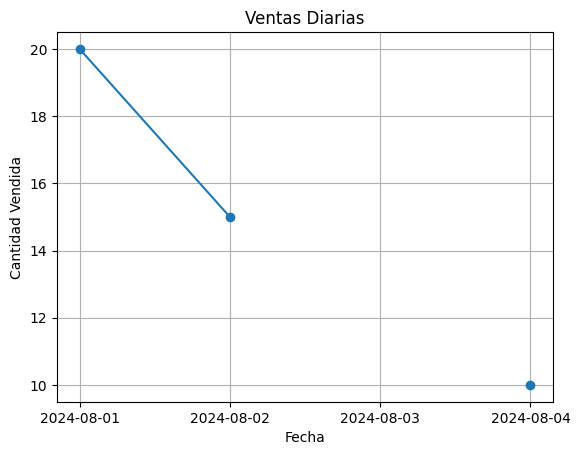

In [3]:
import matplotlib.pyplot as plt

# Gráfico de líneas de las ventas diarias
plt.plot(df['Fecha_venta'], df['Cantidad_vendida'], marker='o')
plt.title('Ventas Diarias')
plt.xlabel('Fecha')
plt.ylabel('Cantidad Vendida')
plt.grid(True)
plt.show()

**NOTA**
  - El corte de la línea se genera ya que en los datos hay valores nulos.
  - `plt.plot()` crea un *gráfico de tipo **plot** o de líneas*.  `marker='o'` añade marcadores en cada punto de la línea (*Véase* parámetro `fmt` del método `plot()`, que define color, marcador y estilo de línea)
  - `plt.show()` muestra el gráfico.

#### Personalización de gráficos

Personalizar gráficos permite *destacar* ciertos aspectos de los datos y hacer que los gráficos sean *más interpretables*.

**Ejemplo práctico**: añadiendo *colores* y *etiquetas* personalizadas.

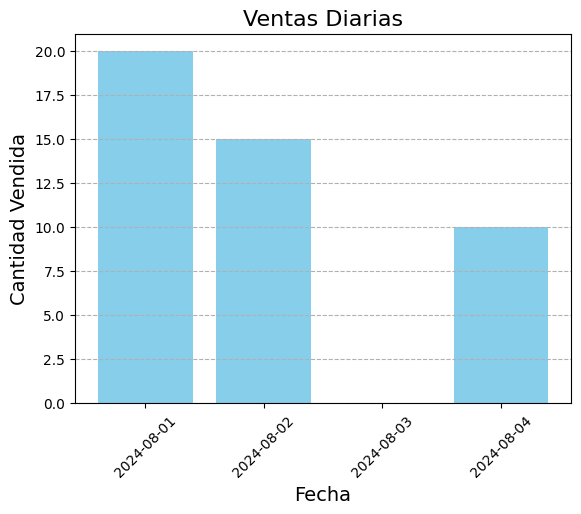

In [4]:
# Gráfico de barras personalizado
plt.bar(df['Fecha_venta'], df['Cantidad_vendida'], color='skyblue')
plt.title('Ventas Diarias', fontsize=16)
plt.xlabel('Fecha', fontsize=14)
plt.ylabel('Cantidad Vendida', fontsize=14)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=1)
plt.show()

**NOTAS**:
  - `color='skyblue'` personaliza el color de las barras. Para conocer más nombres de colores se puede consultar la documentación oficial de Matplotlib ([Enlace](https://matplotlib.org/stable/gallery/color/named_colors.html))
  - `plt.xticks(rotation=45)` rota las etiquetas del eje x para mejorar la legibilidad.
  - `plt.grid(axis='y', linestyle='--', alpha=1)` genera las gradillas de división de los ejes, en este caso solo a lo largo del eje *y* ; `linestyle`, el estilo de línea punteada y el parámetro `alpha` indica el grosor de la línea (Escalar entre 0 y 1)

**Cuándo usarlo**
- Cuando quiero visualizar posibles tendencias de forma rápida

### Creación de Gráficos de Barras Comparativos

**Los gráficos de barras comparativos** se utilizan para comparar diferentes categorías de datos.

**Ejemplo práctico**: Comparar las ventas de diferentes productos.

             Cantidad_vendida Fecha_venta  Precio
ID_producto                                      
1                        20.0  2024-08-01   100.0
2                        15.0  2024-08-02   150.0
3                         0.0  2024-08-03   200.0
4                        10.0  2024-08-04     0.0
5                         0.0  2024-08-05   120.0


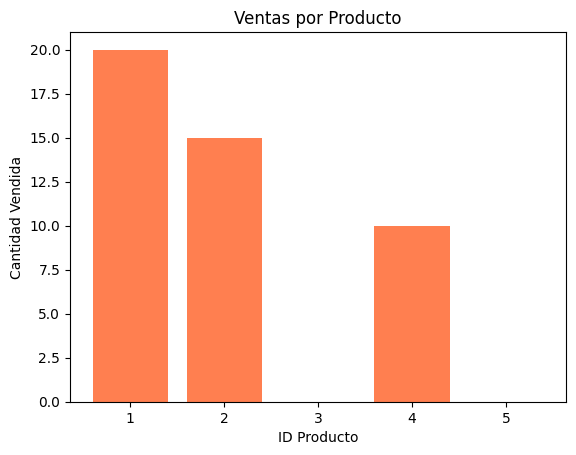

In [5]:
# Agrupar por ID_producto y sumar la cantidad vendida
productos = df.groupby('ID_producto').sum()
print(productos.head())
# Graficar las ventas por producto
plt.bar(productos.index, productos['Cantidad_vendida'], color='coral')
plt.title('Ventas por Producto')
plt.xlabel('ID Producto')
plt.ylabel('Cantidad Vendida')
plt.show()

**NOTA**:
- `df.groupby('ID_producto').sum()` agrupa los datos por producto y suma la cantidad vendida para cada uno.
- `plt.bar(productos.index, productos['Cantidad_vendida'], color='coral')`: crea un gráfico de barras, donde el eje *x* son los `index` del dataframe agrupado (en este caso `ID_producto`); la altura de las barrras es la `cantidad_vendida`; y el color es `coral`.

**Cuándo usarlo**:
- Para comparaciones rápidas
- Cuando no se tienen muchos datos

### Gráficos de Cajas (Boxplots) Comparativos

Los **boxplots** son útiles para mostrar la distribución de los datos y detectar *outliers*.

**Ejemplo Práctico**: Comparar la distribución de precios de diferentes productos.

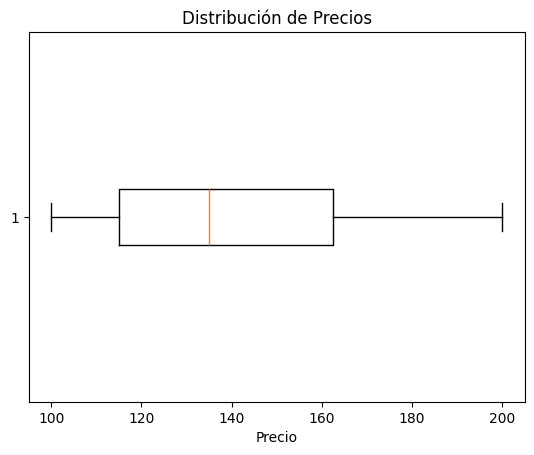

In [6]:
# Gráfico de barras
# Eliminar los valores nulos y graficar el precio
plt.boxplot(df['Precio'].dropna(), vert=False)
plt.title('Distribución de Precios')
plt.xlabel('Precio')
plt.show()

**NOTAS**
- `dropna()` se utiliza para eliminar valores faltantes antes de crear el boxplot.
- `plt.boxplot(df['Precio'].dropna(), vert=False)` genera un gráfico de cajas usando la columna `Precio`.
- El parámetro `vert`indica la orientación del gráfico (`True` para orientación vertical, `False` para orientarlo horizontalmente)

## Uso de Gráficos de Correlación (Heatmaps) - Librería Seaborn

Los **heatmaps** son útiles para visualizar la *correlación* entre diferentes variables.

**Ejemplo Práctico**: Visualizar la correlación entre Cantidad_vendida y Precio.

                  Cantidad_vendida  Precio
Cantidad_vendida               1.0    -1.0
Precio                        -1.0     1.0


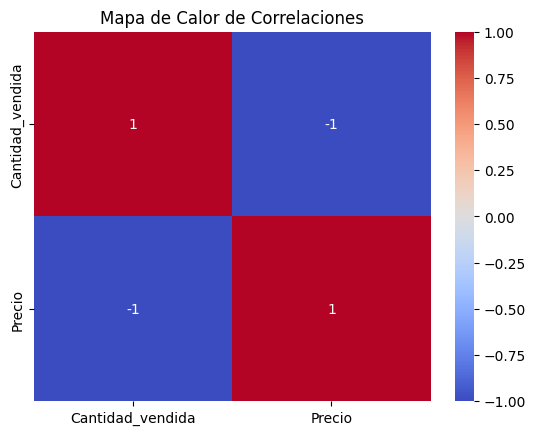

In [7]:
# Importar la librería seaborn
import seaborn as sns

# Estimar la correlación entre las variables numéricas
correlacion = df[['Cantidad_vendida', 'Precio']].corr()
print(correlacion.head())
# Mostrar el mapa de calor de correlaciones
sns.heatmap(correlacion, annot=True, cmap='coolwarm')
plt.title('Mapa de Calor de Correlaciones')
plt.show()


**NOTAS**:
- El método `corr()` genera un dataframe que es la *matriz de correlación* de las columnas, ignorando valores nulos.
- `sns.heatmap()` crea un *mapa de calor* de la matriz de correlación.
- `annot=True` muestra los valores de correlación en cada celda.
- La imagen muestra que existe una *correlación inversa* (valor negativo y cercano a -1) entre la `Cantidad_vendida` y el `Precio`.

### Definición y cálculo de la Matriz de Correlación

La **Matriz de correlación** muestra la relación entre dos o más variables.
  - Los *coeficientes de correlación* indican el grado y la dirección de la relación. Sus valores pueden estar entre -1 y 1.
  - Valores cercanos a 1 indican una relación directamente proporcional, mientras que valores cercanos a -1 indica una relación inversamente proporcional
  - Un valor de 0 indica que no hay correlación fuerte entre las variables.
  - Es importante definir de antemano el criterio de relación fuerte o débil, p. ej. definiendo un límite de >= 0.7 para correlaciones fuertes.

**Coeficiente de Pearson:** Mide la relación *lineal* entre dos variables.
Es útil cuando se quiere saber si un cambio en una variable está asociado con un cambio proporcional en otra.

**Coeficiente de Spearman:** Mide la relación *monótona* entre dos variables,
es decir, si una variable tiende a aumentar (o disminuir) consistentemente cuando la otra lo hace, sin requerir que esa relación sea lineal. Es útil cuando los datos no siguen una distribución normal o contienen valores atípicos.
Spearman se basa en los *rangos de los datos*, no en los valores originales.

In [8]:
# Calcular la matriz de correlación para las variables indicadas
correlacion = df[['ID_producto', 'Cantidad_vendida', 'Precio']].corr(method='pearson')
correlacion

,ID_producto,Cantidad_vendida,Precio
ID_producto,1.000000,-0.981981,0.145847
Cantidad_vendida,-0.981981,1.000000,-1.000000
Precio,0.145847,-1.000000,1.000000


**Resultado**

- `method='pearson'` especifica el método de cálculo de la correlación.
- Valores cercanos a 1 representan una correlación directa entre las variables, valores cercanos a -1 representan una correlación inversa entre las variables y valores cercanos a 0 representan que no existe correlación entre las variables.

### Visualización de la Matriz de Correlación con Seaborn

Mediante el uso de *heatmaps*, **Seaborn** permite visualizar la Matriz de correlación.

**Ejemplo Práctico**

Visualizar la matriz de correlación utilizando Seaborn.

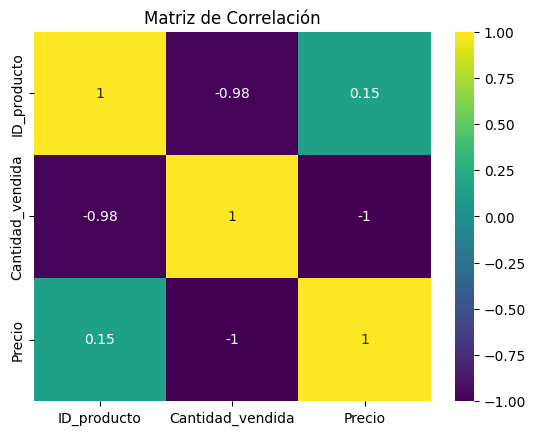

In [9]:
# Visualizar la matriz de correlación
sns.heatmap(correlacion, annot=True, cmap='viridis')
plt.title('Matriz de Correlación')
plt.show()

**Resultado**
- `cmap='viridis'` cambia el esquema de colores utilizado en el heatmap.
- Se puede ver que la correlación entre `Precio` y `Cantidad_vendida` es inversa, lo que se interpretaría que a mayor precio las cantidades vendidas son menores.

## Creación de Gráficos KDE (Kernel Density Estimation) - Librería Seaborn

Los **gráficos KDE** muestran la estimación de la *densidad de probabilidad* de una variable.

**Ejemplo Práctico**: Visualizar la distribución del precio de los productos.

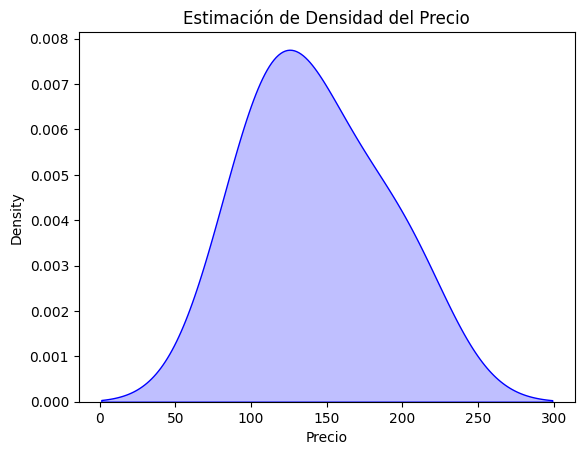

In [11]:
# Gráfico de densidad del precio
# sns.kdeplot(df['Precio'].dropna(), shade=True, color='blue')
sns.kdeplot(df['Precio'].dropna(), fill=True, color='blue')
plt.title('Estimación de Densidad del Precio')
plt.xlabel('Precio')
plt.show()

**Resultado**

- `shade=True` rellena el área bajo la curva., mostrando la densidad de probabilidad de los precios.
- El parámetro `shade` estará deprecado. Se cambia por `fill=True`
- A diferencia de los histogramas, los gráficos KDE no dependen de la elección de los bins.
- Son útiles para detectar la forma de la distribución: si es unimodal, bimodal, sesgada, etc.
- Ayudan a entender mejor la concentración de los datos en ciertos rangos.

### ¿Cómo se calcula un gráfico KDE?

Los gráficos KDE se calculan mediante una técnica llamada** estimación de densidad por núcleo (Kernel Density Estimation)**. Esta técnica permite construir una curva suave que representa la distribución de una variable continua, sin asumir una forma específica como la normal.

**Cálculo**
- **Se selecciona un núcleo (kernel):** El más común es el núcleo gaussiano, que aplica una función de campana centrada en cada punto de los datos.

- **Se define una ventana de suavizado (bandwidth):** Este parámetro controla qué tan suave será la curva. Un bandwidth pequeño produce una curva muy ajustada (más ruido). Un bandwidth grande produce una curva más suave (menos detalle).

- **Se suman las funciones núcleo:** Para cada punto en el eje x, se calcula la suma de todas las funciones núcleo centradas en los datos. El resultado es una curva que representa la densidad de probabilidad estimada.

## Uso de **Violin Plots** para Comparación de Distribuciones - Librería Seaborn

Los **violin plots** combinan **boxplots** y **KDE** para mostrar la distribución de datos.

**Ejemplo Práctico**: Comparar la distribución de precios por ID de producto.

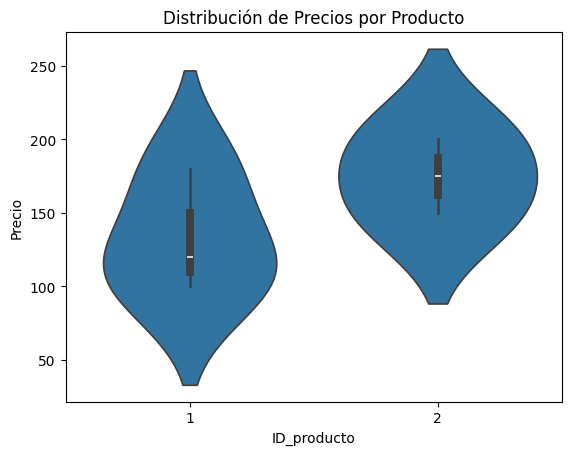

In [12]:
# Cargar el dataset de ventas
data = {
    'ID_producto': [1, 2, 2, 1, 1],
    'Cantidad_vendida': [20, 15, 5, 10, 30],
    'Fecha_venta': ['2024-08-01', '2024-08-02', '2024-08-03', '2024-08-04', '2024-08-05'],
    'Precio': [100, 150, 200, 180, 120]
}

# Crear un dataframe
df = pd.DataFrame(data)

# Grafica de Violin para la distribución de precios por producto
sns.violinplot(x='ID_producto', y='Precio', data=df)
plt.title('Distribución de Precios por Producto')
plt.show()

**Resultado**

- `sns.violinplot()` crea un violin plot para visualizar la distribución de precios por producto. En este caso vemos que el producto 2 tiene una mayor concentración de los precios dado que el violín no es tan *alargado* a comparación de producto 1.

## Introducción al Análisis de Series Temporales

El análisis de series temporales implica el estudio de datos que han sido recolectados a lo largo del tiempo. Este tipo de análisis es crucial para entender patrones y tendencias en datos temporales.

### Visualización de Series Temporales con Matplotlib

**Ejemplo Práctico**: Visualizar las ventas diarias a lo largo del tiempo.

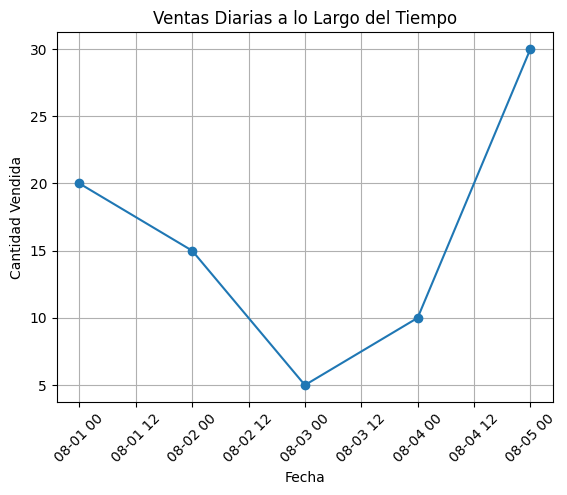

In [14]:
# Convertir la columna 'Fecha_venta' a tipo datetime
df['Fecha_venta'] = pd.to_datetime(df['Fecha_venta'])

# Graficar la cantidad vendida por día
plt.plot(df['Fecha_venta'], df['Cantidad_vendida'], marker='o')
plt.title('Ventas Diarias a lo Largo del Tiempo')
plt.xlabel('Fecha')
plt.ylabel('Cantidad Vendida')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

**Resultado**
- `pd.to_datetime()` convierte las fechas a formato datetime para permitir operaciones de tiempo.
- Se muestran intervalos para la medianoche (mm-dd 00) y el mediodía (mm-dd 12)

## Análisis Exploratorio de Datos (EDA)

El **Análisis Exploratorio de Datos (EDA)** es una fase crítica en el proceso de análisis de datos que permite entender mejor los datos antes de aplicar modelos más complejos.

En esta guía, exploraremos los conceptos básicos del EDA, la preparación y comprensión de datasets, y *cómo automatizar este proceso* utilizando herramientas como `Pandas Profiling` y `Sweetviz`.

También aprenderás a visualizar datos utilizando gráficos básicos, lo que te permitirá identificar *patrones*, *tendencias* y posibles *anomalías*.

### Definición y Objetivos del EDA

**Análisis Exploratorio de Datos (EDA)**: es el proceso mediante el cual se analizan conjuntos de datos para resumir sus principales características, a menudo con métodos visuales.
  - Ayuda a descubrir patrones dentro de los datos.
  - Permite identificar anomalías, valores atípicos y posibles errores en los datos.
  - Todo esto previo a aplicar modelos estadísticos o algoritmos de Machine Learning

**Objetivos del EDA**
  - **Comprender la *distribución* de las variables**: Identificar *patrones* generales en los datos.
  - **Detectar *anomalías* y *outliers*:** Identificar valores que *no se ajustan* a la distribución general.
  - **Explorar *relaciones* entre variables:** Detectar *correlaciones* o *dependencias* entre diferentes variables.
  - **Preparar los datos para *análisis más avanzados*:** *Limpiar* y *transformar* los datos para su posterior uso.

### Importancia del EDA en el Análisis de Datos

El EDA es crucial porque:
  - Permite **descubrir errores** en los datos, sates de que estos errores *afecten a los resultados* del análisis.
  - Informa sobre la **selección de modelos**. al proporcionar una comprensión profunda de las *relaciones y distribuciones* dentro de los datos.
  - **Mejora la interpretación** de los resultados, pues ayuda a *visualizar y comunicar* hallazgos de manera clara y efectiva.

### Fases del EDA: Comprensión Inicial, Visualización y Análisis

El EDA generalmente se divide en **tres fases**:
  1. **Comprensión Inicial**: *Revisión rápida* del conjunto de datos para *familiarizarse* con las variables y los datos en general.
  2. **Visualización**: *Creación de gráficos y visualizaciones* para explorar *patrones* y *relaciones* en los datos.
  3. **Análisis**: *Aplicación de técnicas estadísticas* y exploratorias para obtener insights y preparar los datos para *análisis más complejos*.

### 1. Carga y Comprensión de Datasets

Antes de realizar un EDA, el primer paso es *cargar los datos y obtener una comprensión general del conjunto de datos*. Esto incluye_
  - Revisar las primeras filas,
  - Verificar las dimensiones del dataset y
  - Obtener una visión general de las variables.
